In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

from PIL import Image
from collections import Counter

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Paths (relative to the notebooks/ folder, where this notebook lives)
DATA_DIR = os.path.join("..", "data", "raw")
METADATA_PATH = os.path.join(DATA_DIR, "HAM10000_metadata.csv")

# Confirm the file exists before loading
print("Metadata file exists:", os.path.exists(METADATA_PATH))

# Load
df = pd.read_csv(METADATA_PATH)

# First look
print("Shape:", df.shape)
print("\nColumns:", list(df.columns))
print("\nData types:")
print(df.dtypes)
print("\nFirst 5 rows:")
display(df.head())

Metadata file exists: True
Shape: (10015, 7)

Columns: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']

Data types:
lesion_id           str
image_id            str
dx                  str
dx_type             str
age             float64
sex                 str
localization        str
dtype: object

First 5 rows:


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


In [4]:
# --- Missing values ---
print("Missing values per column:")
missing = df.isnull().sum()
print(missing)
print("\nMissing (%):")
print((df.isnull().mean() * 100).round(2))

# --- Duplicates ---
print("\nFully duplicated rows:", df.duplicated().sum())
print("Duplicated image_id values:", df["image_id"].duplicated().sum())

# --- Unique counts ---
print("\nUnique image_ids :", df["image_id"].nunique())
print("Unique lesion_ids:", df["lesion_id"].nunique())

# --- Categorical value inventory ---
for col in ["dx", "dx_type", "sex", "localization"]:
    print(f"\n{col} value counts:")
    print(df[col].value_counts(dropna=False))

# --- Age range ---
print("\nAge summary:")
print(df["age"].describe())

Missing values per column:
lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
dtype: int64

Missing (%):
lesion_id       0.00
image_id        0.00
dx              0.00
dx_type         0.00
age             0.57
sex             0.00
localization    0.00
dtype: float64

Fully duplicated rows: 0
Duplicated image_id values: 0

Unique image_ids : 10015
Unique lesion_ids: 7470

dx value counts:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64

dx_type value counts:
dx_type
histo        5340
follow_up    3704
consensus     902
confocal       69
Name: count, dtype: int64

sex value counts:
sex
male       5406
female     4552
unknown      57
Name: count, dtype: int64

localization value counts:
localization
back               2192
lower extremity    2077
trunk              1404
upper extremity    1118
abdomen            1022
face         

In [5]:
for col in ["dx", "dx_type", "sex"]:
    print(f"\n{col} value counts:")
    print(df[col].value_counts(dropna=False).to_string())

print("\nlocalization value counts:")
print(df["localization"].value_counts(dropna=False).to_string())

print("\nAge summary:")
print(df["age"].describe().to_string())


dx value counts:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115

dx_type value counts:
dx_type
histo        5340
follow_up    3704
consensus     902
confocal       69

sex value counts:
sex
male       5406
female     4552
unknown      57

localization value counts:
localization
back               2192
lower extremity    2077
trunk              1404
upper extremity    1118
abdomen            1022
face                745
chest               407
foot                319
unknown             234
neck                168
scalp               128
hand                 90
ear                  56
genital              48
acral                 7

Age summary:
count    9958.000000
mean       51.863828
std        16.968614
min         0.000000
25%        40.000000
50%        50.000000
75%        65.000000
max        85.000000


Rows with unknown sex AND missing age: 47

Imbalance ratio (largest/smallest): 58.3


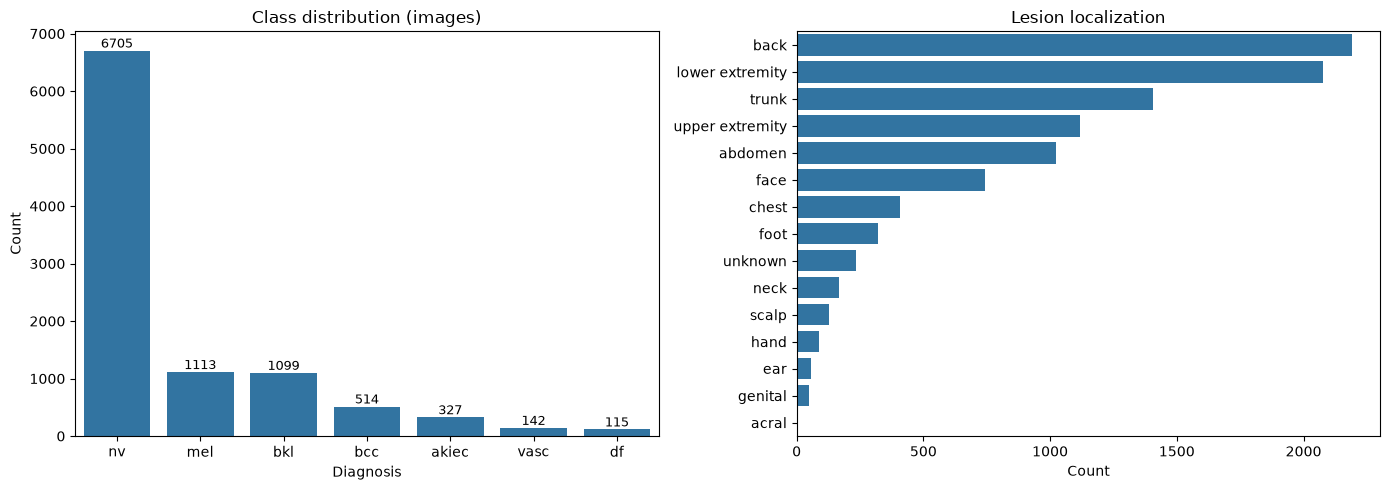

In [6]:
# Do the 57 unknown-sex rows coincide with the 57 missing-age rows?
both = df[(df["sex"] == "unknown") & (df["age"].isnull())].shape[0]
print("Rows with unknown sex AND missing age:", both)

# Class distribution
order = df["dx"].value_counts().index
counts = df["dx"].value_counts()
print("\nImbalance ratio (largest/smallest):", round(counts.max() / counts.min(), 1))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df, x="dx", order=order, ax=axes[0])
axes[0].set_title("Class distribution (images)")
axes[0].set_xlabel("Diagnosis")
axes[0].set_ylabel("Count")
for p in axes[0].patches:
    axes[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom", fontsize=9)

loc_order = df["localization"].value_counts().index
sns.countplot(data=df, y="localization", order=loc_order, ax=axes[1])
axes[1].set_title("Lesion localization")
axes[1].set_xlabel("Count")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

In [7]:
# Images per lesion
imgs_per_lesion = df.groupby("lesion_id")["image_id"].count()
print("Images per lesion - distribution:")
print(imgs_per_lesion.value_counts().sort_index().to_string())

multi = imgs_per_lesion[imgs_per_lesion > 1]
print("\nLesions with >1 image:", len(multi), "of", len(imgs_per_lesion))
print("Images belonging to multi-image lesions:", multi.sum(), "of", len(df))

# Does any lesion have more than one diagnosis label? (would break lesion-level stratification)
dx_per_lesion = df.groupby("lesion_id")["dx"].nunique()
print("\nLesions with conflicting dx labels:", (dx_per_lesion > 1).sum())

# Per-class: unique lesions vs images
lesion_df = df.drop_duplicates("lesion_id")[["lesion_id", "dx"]]
summary = pd.DataFrame({
    "images": df["dx"].value_counts(),
    "lesions": lesion_df["dx"].value_counts(),
})
summary["images_per_lesion"] = (summary["images"] / summary["lesions"]).round(2)
print("\nPer-class images vs unique lesions:")
print(summary.to_string())

Images per lesion - distribution:
image_id
1    5514
2    1423
3     490
4      34
5       5
6       4

Lesions with >1 image: 1956 of 7470
Images belonging to multi-image lesions: 4501 of 10015

Lesions with conflicting dx labels: 0

Per-class images vs unique lesions:
       images  lesions  images_per_lesion
dx                                       
akiec     327      228               1.43
bcc       514      327               1.57
bkl      1099      727               1.51
df        115       73               1.58
mel      1113      614               1.81
nv       6705     5403               1.24
vasc      142       98               1.45


In [8]:
image_dirs = ["HAM10000_images_part_1", "HAM10000_images_part_2"]

path_map = {}
dupes = []
per_folder = {}

for d in image_dirs:
    full = os.path.join(DATA_DIR, d)
    count = 0
    for root, _, files in os.walk(full):   # os.walk also handles accidental nested folders
        for f in files:
            if f.lower().endswith(".jpg"):
                stem = os.path.splitext(f)[0]
                if stem in path_map:
                    dupes.append(stem)
                path_map[stem] = os.path.join(root, f)
                count += 1
    per_folder[d] = count

print("JPG files per folder:", per_folder)
print("Total unique image files on disk:", len(path_map))
print("Same filename in both folders:", len(dupes))

meta_ids = set(df["image_id"])
disk_ids = set(path_map)
print("\nIn metadata but not on disk:", len(meta_ids - disk_ids))
print("On disk but not in metadata:", len(disk_ids - meta_ids))

# Attach file paths to the dataframe
df["path"] = df["image_id"].map(path_map)
print("Rows without a path:", df["path"].isnull().sum())

# Check a random sample of 200 images: size and color mode
sample = df.sample(200, random_state=42)
sizes, modes = Counter(), Counter()
for p in sample["path"]:
    with Image.open(p) as im:
        sizes[im.size] += 1      # (width, height)
        modes[im.mode] += 1
print("\nSampled image sizes (w, h):", dict(sizes))
print("Sampled color modes:", dict(modes))

JPG files per folder: {'HAM10000_images_part_1': 5000, 'HAM10000_images_part_2': 5015}
Total unique image files on disk: 10015
Same filename in both folders: 0

In metadata but not on disk: 0
On disk but not in metadata: 0
Rows without a path: 0

Sampled image sizes (w, h): {(600, 450): 200}
Sampled color modes: {'RGB': 200}


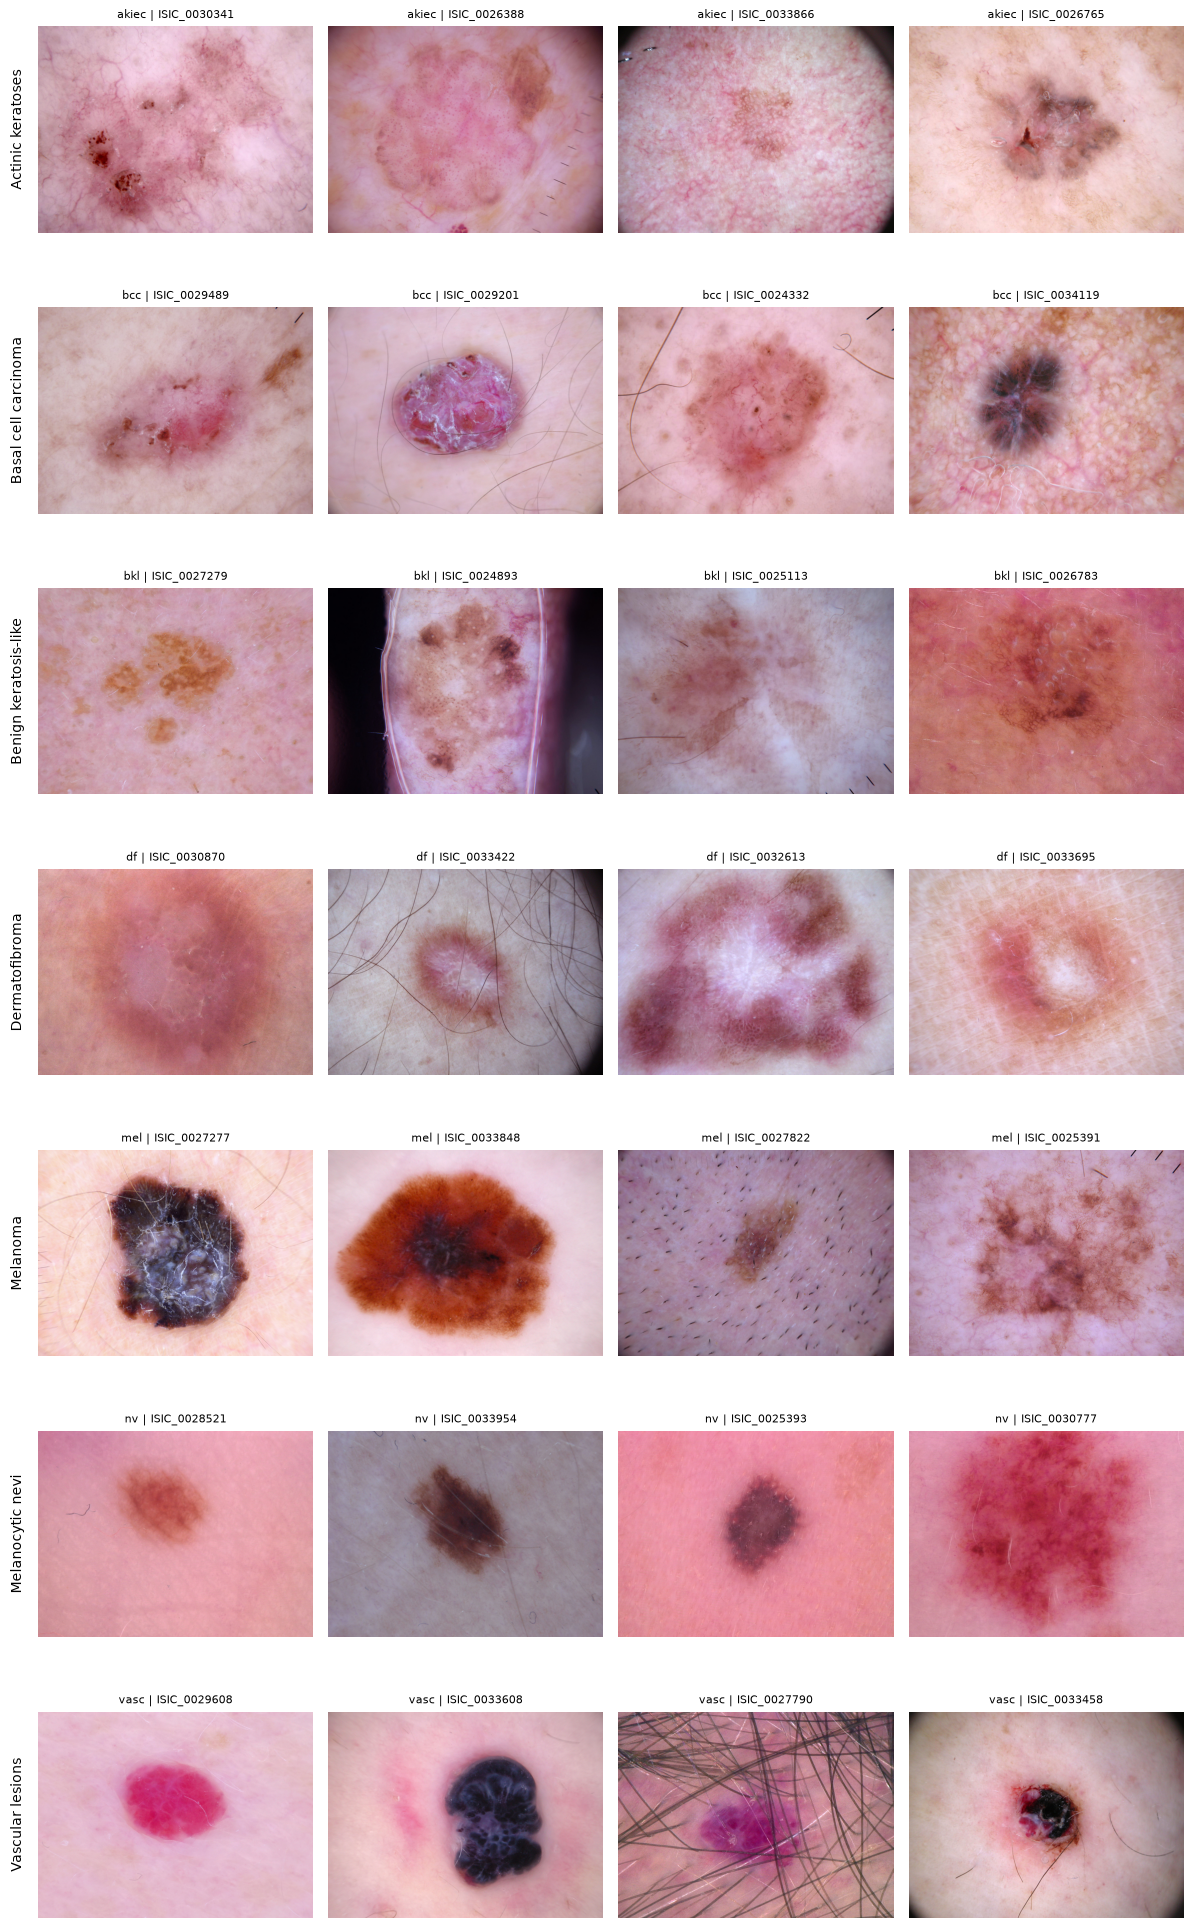

In [9]:
class_names = {
    "akiec": "Actinic keratoses",
    "bcc": "Basal cell carcinoma",
    "bkl": "Benign keratosis-like",
    "df": "Dermatofibroma",
    "mel": "Melanoma",
    "nv": "Melanocytic nevi",
    "vasc": "Vascular lesions",
}

n_per_class = 4
fig, axes = plt.subplots(len(class_names), n_per_class, figsize=(12, 20))

for row, (dx, full_name) in enumerate(class_names.items()):
    samples = df[df["dx"] == dx].sample(n_per_class, random_state=7)
    for col, (_, r) in enumerate(samples.iterrows()):
        img = Image.open(r["path"]).convert("RGB")
        axes[row, col].imshow(img)
        axes[row, col].axis("off")
        axes[row, col].set_title(f"{dx} | {r['image_id']}", fontsize=8)
    axes[row, 0].text(-0.05, 0.5, full_name, transform=axes[row, 0].transAxes,
                      rotation=90, va="center", ha="right", fontsize=10)

plt.tight_layout()
plt.show()

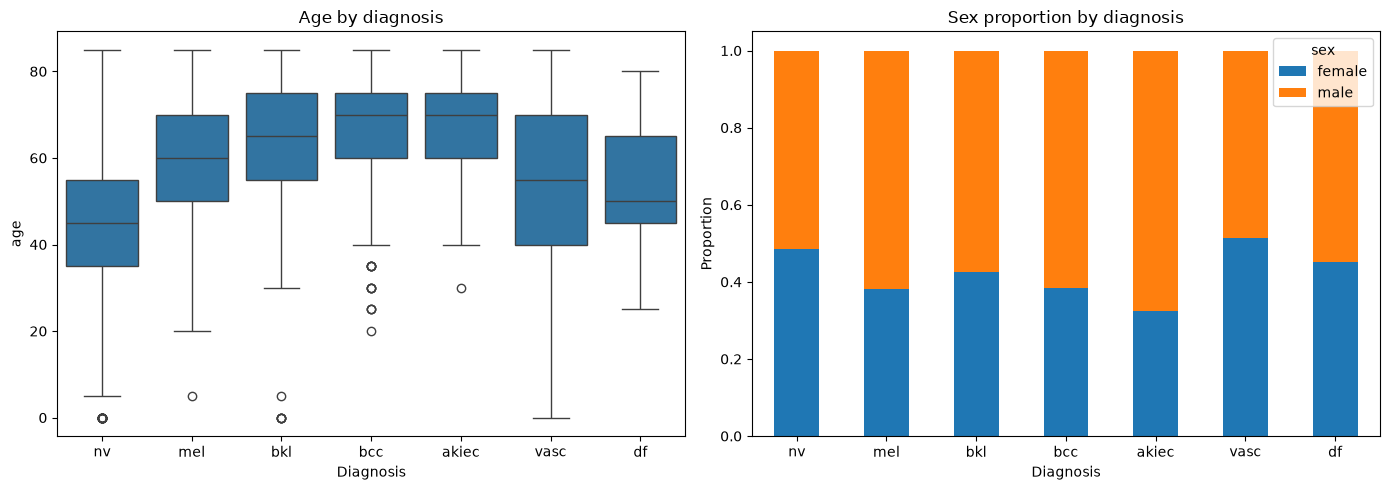

Median age by class:
dx
nv       45.0
df       50.0
vasc     55.0
mel      60.0
bkl      65.0
bcc      70.0
akiec    70.0


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Age distribution per class (missing ages are ignored automatically)
sns.boxplot(data=df, x="dx", y="age", order=df["dx"].value_counts().index, ax=axes[0])
axes[0].set_title("Age by diagnosis")
axes[0].set_xlabel("Diagnosis")

# Sex proportion per class (excluding unknown)
known = df[df["sex"] != "unknown"]
sex_prop = pd.crosstab(known["dx"], known["sex"], normalize="index")
sex_prop = sex_prop.loc[df["dx"].value_counts().index]
sex_prop.plot(kind="bar", stacked=True, ax=axes[1])
axes[1].set_title("Sex proportion by diagnosis")
axes[1].set_xlabel("Diagnosis")
axes[1].set_ylabel("Proportion")
axes[1].legend(title="sex")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

print("Median age by class:")
print(df.groupby("dx")["age"].median().sort_values().to_string())

In [11]:
from sklearn.model_selection import StratifiedShuffleSplit

SEED = 42

# One row per lesion (labels are unique per lesion, verified earlier)
lesions = df.drop_duplicates("lesion_id")[["lesion_id", "dx"]].reset_index(drop=True)

# Step A: carve out 70% train vs 30% temp, stratified by dx
sss1 = StratifiedShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
train_idx, temp_idx = next(sss1.split(lesions, lesions["dx"]))
train_lesions = lesions.iloc[train_idx]
temp_lesions = lesions.iloc[temp_idx]

# Step B: split temp 50/50 into val and test (15% / 15% overall)
sss2 = StratifiedShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
val_idx, test_idx = next(sss2.split(temp_lesions, temp_lesions["dx"]))
val_lesions = temp_lesions.iloc[val_idx]
test_lesions = temp_lesions.iloc[test_idx]

# Map lesion-level assignment back to images
split_map = {}
for name, part in [("train", train_lesions), ("val", val_lesions), ("test", test_lesions)]:
    for lid in part["lesion_id"]:
        split_map[lid] = name
df["split"] = df["lesion_id"].map(split_map)

# --- Verification ---
print("Rows without a split:", df["split"].isnull().sum())

# Leakage check: no lesion may appear in more than one split
splits_per_lesion = df.groupby("lesion_id")["split"].nunique()
print("Lesions appearing in >1 split:", (splits_per_lesion > 1).sum())

print("\nLesions per split:")
print(df.drop_duplicates("lesion_id")["split"].value_counts().to_string())
print("\nImages per split:")
print(df["split"].value_counts().to_string())
print("\nImage share per split (%):")
print((df["split"].value_counts(normalize=True) * 100).round(1).to_string())

print("\nImages per class per split:")
print(pd.crosstab(df["dx"], df["split"])[["train", "val", "test"]].to_string())

Rows without a split: 0
Lesions appearing in >1 split: 0

Lesions per split:
split
train    5229
test     1121
val      1120

Images per split:
split
train    7002
val      1532
test     1481

Image share per split (%):
split
train    69.9
val      15.3
test     14.8

Images per class per split:
split  train   val  test
dx                      
akiec    230    51    46
bcc      366    77    71
bkl      774   157   168
df        76    19    20
mel      778   170   165
nv      4679  1034   992
vasc      99    24    19


In [12]:
PROJECT_ROOT = os.path.abspath("..")
PROCESSED_DIR = os.path.join(PROJECT_ROOT, "data", "processed")
os.makedirs(PROCESSED_DIR, exist_ok=True)

# Store paths relative to the project root so the file works from any notebook/script
out = df[["lesion_id", "image_id", "dx", "split", "path"]].copy()
out["path"] = out["path"].apply(
    lambda p: os.path.relpath(os.path.abspath(p), PROJECT_ROOT).replace("\\", "/")
)
SPLIT_PATH = os.path.join(PROCESSED_DIR, "split_v1.csv")
out.to_csv(SPLIT_PATH, index=False)

# Reload and verify it round-trips
chk = pd.read_csv(SPLIT_PATH)
print("Saved to:", SPLIT_PATH)
print("Shape:", chk.shape)
print("Splits:", chk["split"].value_counts().to_dict())
print("Lesions in >1 split:", (chk.groupby("lesion_id")["split"].nunique() > 1).sum())
print("First path:", chk["path"].iloc[0])
print("All paths exist:", all(os.path.exists(os.path.join(PROJECT_ROOT, p)) for p in chk["path"]))

# The rows that were cut off last time, printed in small pieces
ct = pd.crosstab(chk["dx"], chk["split"])[["train", "val", "test"]]
print("\nbcc:", ct.loc["bcc"].to_dict())
print("bkl:", ct.loc["bkl"].to_dict())
print("akiec:", ct.loc["akiec"].to_dict())

Saved to: <project>\data\processed\split_v1.csv
Shape: (10015, 5)
Splits: {'train': 7002, 'val': 1532, 'test': 1481}
Lesions in >1 split: 0
First path: data/raw/HAM10000_images_part_1/ISIC_0027419.jpg
All paths exist: True

bcc: {'train': 366, 'val': 77, 'test': 71}
bkl: {'train': 774, 'val': 157, 'test': 168}
akiec: {'train': 230, 'val': 51, 'test': 46}
